Loading MNIST dataset...
Applying UMAP (this may take a few minutes)...


c:\Users\TGawade\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


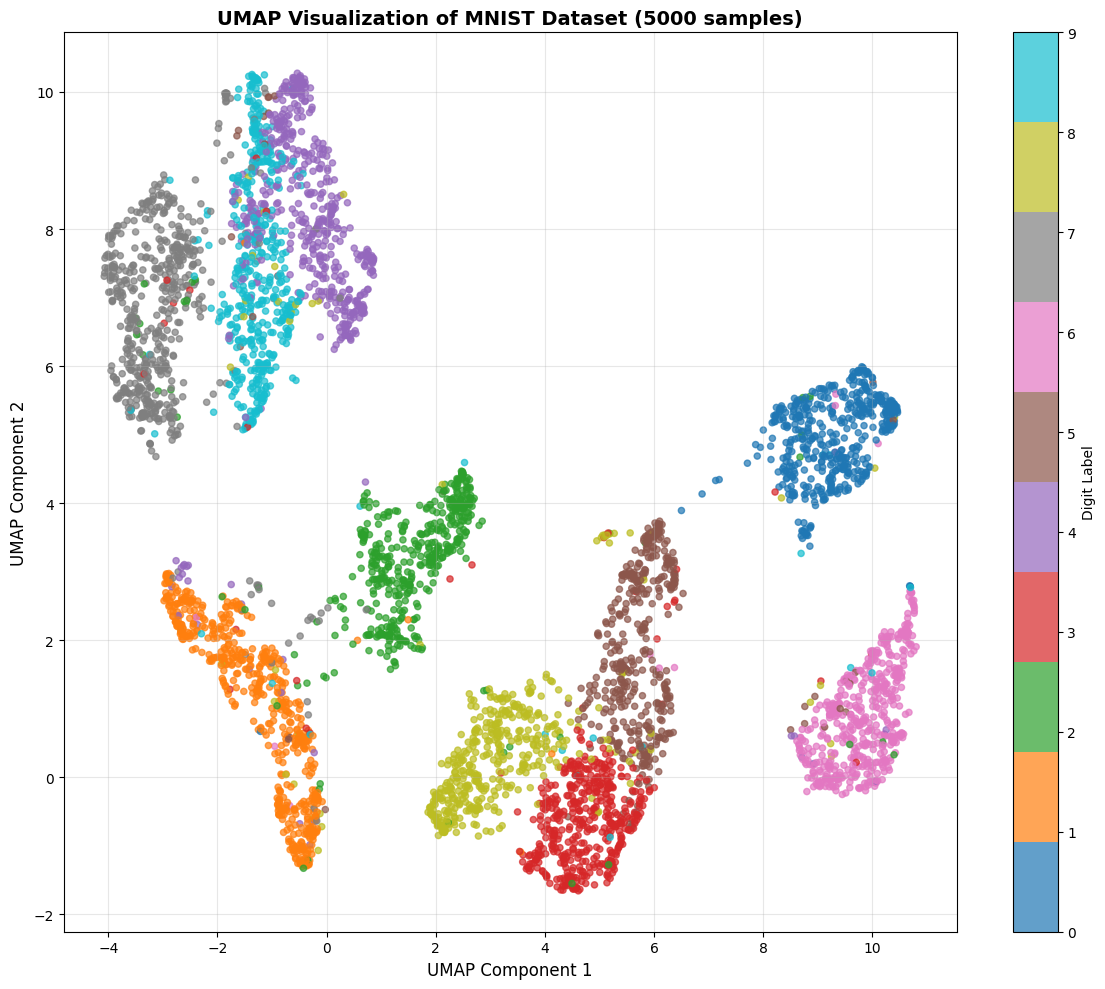

UMAP visualization complete!

UMAP Parameters:
  - Input dimensions: 784
  - Output dimensions: 2
  - Number of samples: 5000
  - Number of neighbors: 15
  - Minimum distance: 0.1


In [5]:
import matplotlib.pyplot as plt          # For plotting and visualization
from sklearn.datasets import fetch_openml  # To load MNIST dataset
import umap                              # UMAP dimensionality reduction library
import numpy as np                       # For numerical operations

# Load the MNIST dataset (70,000 samples of 28x28 images)
print("Loading MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
# fetch_openml: Downloads MNIST dataset from OpenML repository
# 'mnist_784': Each image is 28x28 pixels flattened to 784 features
# version=1: Use the original MNIST version
# as_frame=False: Return as numpy arrays, not pandas DataFrames

X = mnist.data                          # Feature matrix: shape (70000, 784)
                                        # Each row represents one handwritten digit image
                                        # Each column represents one pixel value (0-255)
                                        
y = mnist.target.astype(int)            # Labels: shape (70000,)
                                        # Convert from string to integer (0-9)
                                        # Each label tells us which digit the image represents

# Use a subset for faster computation
# UMAP is faster than t-SNE but still takes time on large datasets
n_samples = 5000                        # Number of samples to use (out of 70,000)
X_subset = X[:n_samples]                # Take first 5000 images: shape (5000, 784)
y_subset = y[:n_samples]                # Take first 5000 labels: shape (5000,)

# Normalize the data to [0, 1] range
X_subset = X_subset / 255.0             # Pixel values are 0-255
                                        # Divide by 255 to get values between 0 and 1
                                        # Normalization helps UMAP work better

# Apply UMAP to reduce dimensionality from 784D to 2D
print("Applying UMAP (this may take a few minutes)...")
umap_reducer = umap.UMAP(
    n_components=2,                     # Reduce to 2 dimensions for visualization
                                        # Output will be (n_samples, 2)
    
    n_neighbors=15,                     # Number of neighbors to consider for each point
                                        # Controls local vs global structure balance
                                        # Smaller: focuses on local structure
                                        # Larger: focuses on global structure
                                        # Typical range: 5-50
    
    min_dist=0.1,                       # Minimum distance between points in low-dim space
                                        # Controls how tightly points can be packed
                                        # Smaller: tighter clusters
                                        # Larger: more spread out
                                        # Typical range: 0.0-0.99
    
    metric='euclidean',                 # Distance metric to use in high-dim space
                                        # 'euclidean': standard L2 distance
                                        # Other options: 'manhattan', 'cosine', etc.
    
    random_state=42                     # Set seed for reproducibility
                                        # Same seed = same results every time
)

# Transform the data: 784 dimensions → 2 dimensions
X_umap = umap_reducer.fit_transform(X_subset)
# fit_transform: Learn the UMAP embedding and transform the data
# Input: (5000, 784) → Output: (5000, 2)
# Each 784-dimensional point is now mapped to a 2D coordinate

# Visualize the UMAP results
plt.figure(figsize=(12, 10))            # Create a figure with size 12x10 inches

scatter = plt.scatter(
    X_umap[:, 0],                       # X-axis: first UMAP component
                                        # X_umap[:, 0] extracts first column (all rows)
    
    X_umap[:, 1],                       # Y-axis: second UMAP component
                                        # X_umap[:, 1] extracts second column (all rows)
    
    c=y_subset,                         # Color points by their digit label (0-9)
                                        # Each digit gets a different color
    
    cmap='tab10',                       # Colormap with 10 distinct colors
                                        # 'tab10': Tableau's 10-color palette
                                        # Perfect for 10 digit classes (0-9)
    
    alpha=0.7,                          # Set transparency to 0.7 (70% opaque)
                                        # Helps see overlapping points
    
    s=20                                # Set point size to 20
                                        # s: marker size in points²
)

# Add axis labels
plt.xlabel('UMAP Component 1', fontsize=12)  # Label for x-axis
plt.ylabel('UMAP Component 2', fontsize=12)  # Label for y-axis

# Add title
plt.title(f'UMAP Visualization of MNIST Dataset ({n_samples} samples)', 
          fontsize=14, fontweight='bold')
# f-string: inserts n_samples value into the title
# fontsize=14: larger title font
# fontweight='bold': make title bold

# Add colorbar legend
plt.colorbar(scatter, label='Digit Label')
# Shows which color corresponds to which digit (0-9)
# label='Digit Label': adds a label to the colorbar

# Add grid for better readability
plt.grid(True, alpha=0.3)               # Add grid lines
                                        # alpha=0.3: make grid 30% opaque (subtle)

# Adjust layout to prevent label cutoff
plt.tight_layout()                      # Automatically adjust spacing

# Display the plot
plt.show()                              # Render and show the visualization

print("UMAP visualization complete!")
# Print completion message

# Optional: Print some statistics
print("\nUMAP Parameters:")
print(f"  - Input dimensions: {X_subset.shape[1]}")      # 784
print(f"  - Output dimensions: {X_umap.shape[1]}")       # 2
print(f"  - Number of samples: {X_umap.shape[0]}")       # 5000
print(f"  - Number of neighbors: {umap_reducer.n_neighbors}")  # 15
print(f"  - Minimum distance: {umap_reducer.min_dist}")        # 0.1

In [4]:
pip install umap-learn


   -------------------- ------------------- 1/2 [umap-learn]
   ---------------------------------------- 2/2 [umap-learn]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip
